In [1]:
# Cell 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import shap
import joblib
import json
import os

from sklearn.model_selection import StratifiedGroupKFold

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")
print("SHAP version:", shap.__version__)

All libraries imported successfully!
SHAP version: 0.54.1


In [2]:
# Cell 2: Load Dataset, Model and Metadata

df = pd.read_csv(
    "../data/processed/usgs_inventory_missing_cleaned.csv"
)

model = joblib.load(
    "../models/afterburn_logistic_regression.joblib"
)

with open("../models/model_metadata.json", "r") as file:
    metadata = json.load(file)

features = metadata["features"]
threshold = metadata["threshold"]

print("Dataset loaded:", df.shape)
print("Model loaded:", metadata["model_name"])
print("Number of features:", len(features))
print("Classification threshold:", threshold)

Dataset loaded: (8981, 37)
Model loaded: Logistic Regression - Reduced Features
Number of features: 10
Classification threshold: 0.47


In [3]:
# Cell 3: Recreate Development and Holdout Split

y = df["Response"]
groups = df["FireName"]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

train_idx, test_idx = next(
    cv.split(df, y, groups)
)

X_dev = df.iloc[train_idx][features].copy()
X_holdout = df.iloc[test_idx][features].copy()

y_dev = y.iloc[train_idx].copy()
y_holdout = y.iloc[test_idx].copy()

groups_dev = groups.iloc[train_idx]
groups_holdout = groups.iloc[test_idx]

print("Development shape:", X_dev.shape)
print("Holdout shape:", X_holdout.shape)

print("Development wildfire groups:", groups_dev.nunique())
print("Holdout wildfire groups:", groups_holdout.nunique())

print(
    "Overlapping wildfire groups:",
    len(set(groups_dev) & set(groups_holdout))
)

Development shape: (6241, 10)
Holdout shape: (2740, 10)
Development wildfire groups: 69
Holdout wildfire groups: 11
Overlapping wildfire groups: 0


In [4]:
# Cell 4: Prepare Data for SHAP Analysis

# Extract fitted preprocessing components
imputer = model.named_steps["imputer"]
scaler = model.named_steps["scaler"]
logistic_model = model.named_steps["model"]

# Select 200 background observations
background_data = X_dev.sample(
    n=200,
    random_state=42
)

# Transform background observations
background_imputed = imputer.transform(
    background_data
)

background_scaled = scaler.transform(
    background_imputed
)

# Transform holdout observations
holdout_imputed = imputer.transform(
    X_holdout
)

holdout_scaled = scaler.transform(
    holdout_imputed
)

# Preserve original feature values for visualisation
holdout_display_df = pd.DataFrame(
    holdout_imputed,
    columns=features,
    index=X_holdout.index
)

print("SHAP data prepared successfully!")

print("Background data shape:", background_scaled.shape)
print("Holdout data shape:", holdout_scaled.shape)
print("Feature names:", features)

SHAP data prepared successfully!
Background data shape: (200, 10)
Holdout data shape: (2740, 10)
Feature names: ['StormAccumulation', 'StormDuration', 'PeakI60', 'RainfallRatio60', 'HM23', 'dNBR/1000', 'KF', 'UpstreamArea', 'DaysSinceFire', 'YearAfterFire']


In [5]:
# Cell 5: Calculate SHAP Values

explainer = shap.LinearExplainer(
    logistic_model,
    background_scaled,
    feature_perturbation="interventional"
)

shap_values = explainer.shap_values(
    holdout_scaled
)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

if shap_values.ndim == 3:
    if shap_values.shape[0] == len(holdout_scaled):
        shap_values = shap_values[:, :, -1]
    else:
        shap_values = shap_values[-1]

print("SHAP values generated successfully!")
print("SHAP values shape:", shap_values.shape)

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


SHAP values generated successfully!
SHAP values shape: (2740, 10)


In [6]:
# Cell 6: Global SHAP Feature Importance

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "Feature": features,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance_df = shap_importance_df.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("GLOBAL SHAP FEATURE IMPORTANCE")

display(shap_importance_df.round(4))

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,PeakI60,0.6215
1,UpstreamArea,0.5647
2,YearAfterFire,0.5369
3,HM23,0.4842
4,StormDuration,0.4240
5,RainfallRatio60,0.3679
6,DaysSinceFire,0.2656
7,dNBR/1000,0.1601
8,StormAccumulation,0.1177
9,KF,0.0164


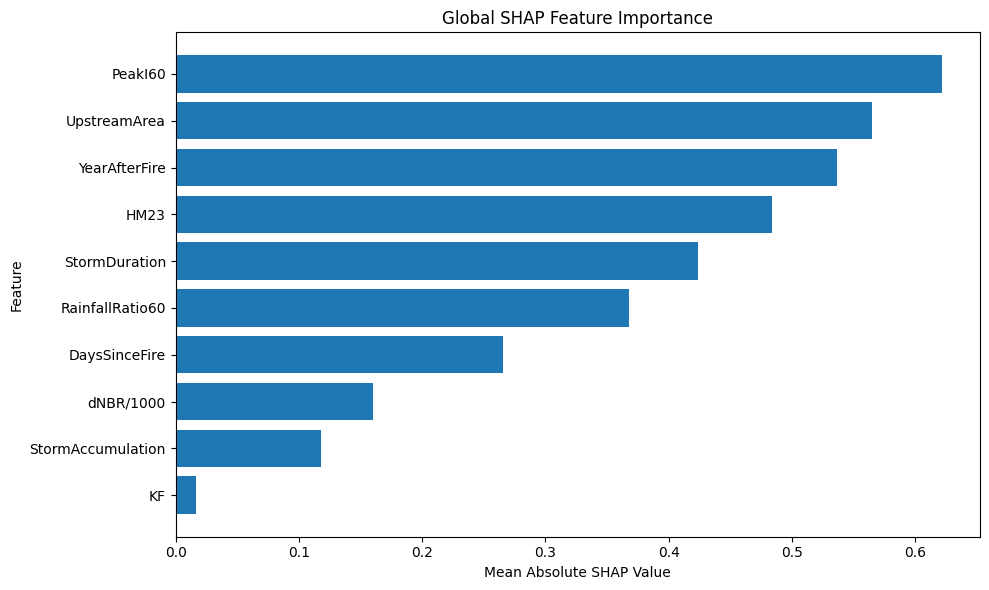

In [7]:
# Cell 7: Global SHAP Importance Plot

plot_df = shap_importance_df.sort_values(
    "Mean_Absolute_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance")

plt.tight_layout()
plt.show()

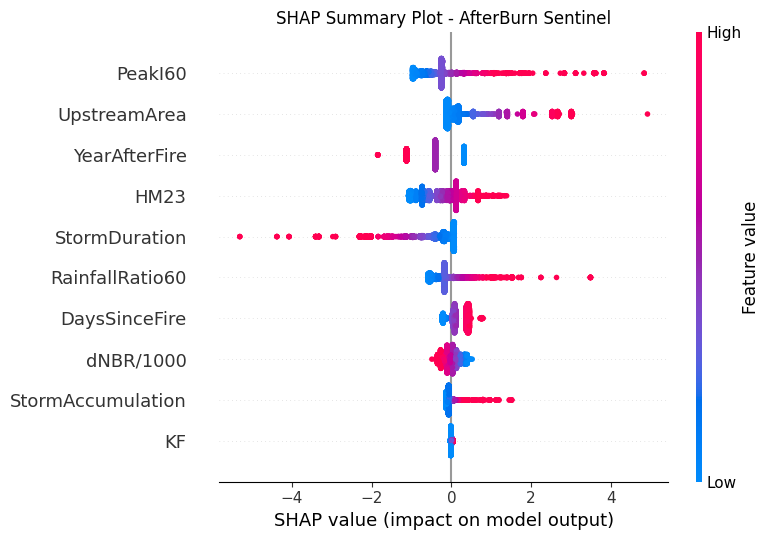

In [8]:
# Cell 8: SHAP Summary / Beeswarm Plot

shap.summary_plot(
    shap_values,
    features=holdout_display_df,
    feature_names=features,
    max_display=10,
    show=False
)

plt.title("SHAP Summary Plot - AfterBurn Sentinel")
plt.tight_layout()
plt.show()

In [9]:
# Cell 9: Select True Positive and False Negative Cases

# Generate predictions using the saved model
holdout_probabilities = model.predict_proba(
    X_holdout
)[:, 1]

holdout_predictions = (
    holdout_probabilities >= threshold
).astype(int)

# Find correctly detected positive observations
tp_positions = np.where(
    (y_holdout.to_numpy() == 1) &
    (holdout_predictions == 1)
)[0]

# Find missed positive observations
fn_positions = np.where(
    (y_holdout.to_numpy() == 1) &
    (holdout_predictions == 0)
)[0]

if len(tp_positions) == 0 or len(fn_positions) == 0:
    raise ValueError("Required prediction categories are missing.")

# Select highest-probability true positive
tp_position = tp_positions[
    np.argmax(holdout_probabilities[tp_positions])
]

# Select lowest-probability false negative
fn_position = fn_positions[
    np.argmin(holdout_probabilities[fn_positions])
]

print("TRUE POSITIVE OBSERVATION")
print("-------------------------")
print("Wildfire:",
      df.iloc[test_idx[tp_position]]["FireName"])
print("Actual response:", y_holdout.iloc[tp_position])
print("Predicted response:", holdout_predictions[tp_position])
print("Probability:",
      round(holdout_probabilities[tp_position], 4))

print("\nFALSE NEGATIVE OBSERVATION")
print("--------------------------")
print("Wildfire:",
      df.iloc[test_idx[fn_position]]["FireName"])
print("Actual response:", y_holdout.iloc[fn_position])
print("Predicted response:", holdout_predictions[fn_position])
print("Probability:",
      round(holdout_probabilities[fn_position], 4))

TRUE POSITIVE OBSERVATION
-------------------------
Wildfire: Grizzly Creek
Actual response: 1
Predicted response: 1
Probability: 0.9995

FALSE NEGATIVE OBSERVATION
--------------------------
Wildfire: Cameron Peak
Actual response: 1
Predicted response: 0
Probability: 0.0592


In [10]:
# Cell 10: Create Individual SHAP Explanations

base_value = float(
    np.asarray(explainer.expected_value).reshape(-1)[-1]
)

tp_explanation = shap.Explanation(
    values=shap_values[tp_position],
    base_values=base_value,
    data=holdout_display_df.iloc[tp_position].to_numpy(),
    feature_names=features
)

fn_explanation = shap.Explanation(
    values=shap_values[fn_position],
    base_values=base_value,
    data=holdout_display_df.iloc[fn_position].to_numpy(),
    feature_names=features
)

print("Individual SHAP explanations created successfully!")

Individual SHAP explanations created successfully!


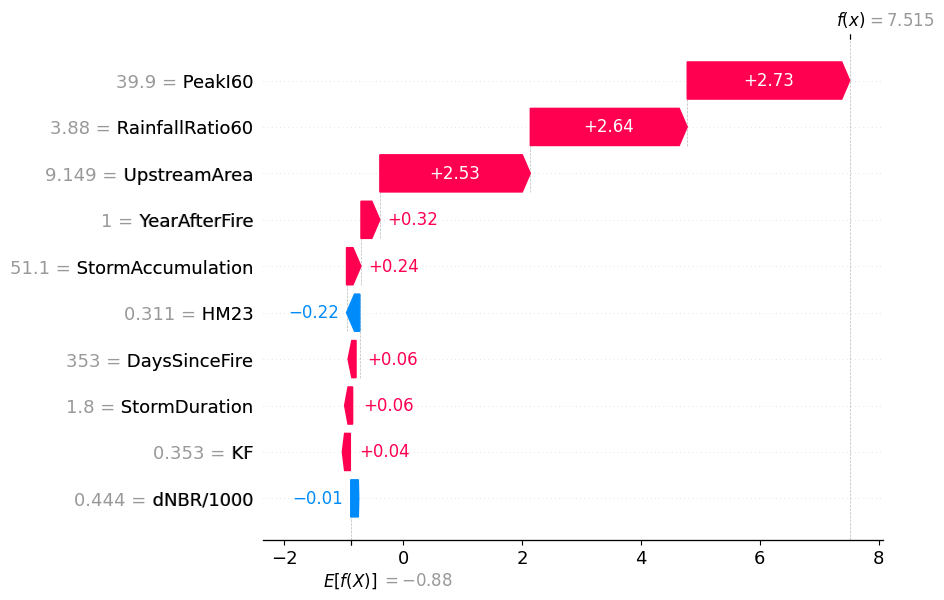

In [11]:
# Cell 11: True Positive Waterfall Plot

shap.plots.waterfall(
    tp_explanation,
    max_display=10
)

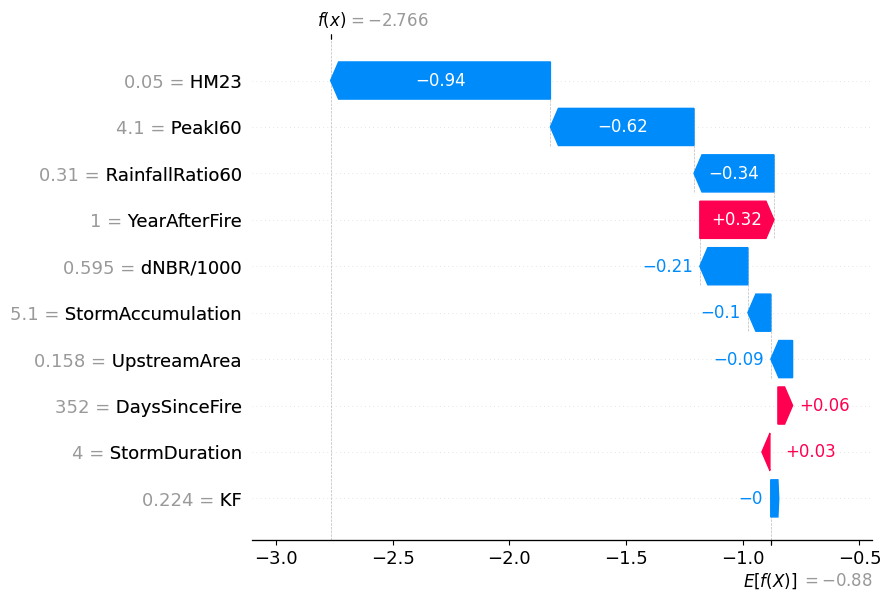

In [12]:
# Cell 12: False Negative Waterfall Plot

shap.plots.waterfall(
    fn_explanation,
    max_display=10
)


In [13]:
# Cell 13: Export SHAP Results

os.makedirs("../outputs", exist_ok=True)

# 1. Export global feature importance
shap_importance_df.to_csv(
    "../outputs/shap_global_importance.csv",
    index=False
)

# 2. Export individual SHAP contributions
shap_contributions = pd.DataFrame(
    shap_values,
    columns=[f"SHAP_{feature}" for feature in features]
)

observation_info = df.iloc[test_idx][
    ["FireName", "FireState", "UniqueObservationID"]
].reset_index(drop=True)

observation_info["Actual_Response"] = y_holdout.to_numpy()
observation_info["Predicted_Response"] = holdout_predictions
observation_info["Predicted_Probability"] = holdout_probabilities

shap_export = pd.concat(
    [observation_info, shap_contributions],
    axis=1
)

shap_export.to_csv(
    "../outputs/shap_holdout_contributions.csv",
    index=False
)

# 3. Export summary of the selected examples
individual_examples = pd.DataFrame([
    {
        "Case": "True Positive",
        "FireName": df.iloc[test_idx[tp_position]]["FireName"],
        "Actual_Response": int(y_holdout.iloc[tp_position]),
        "Predicted_Response": int(holdout_predictions[tp_position]),
        "Predicted_Probability": holdout_probabilities[tp_position]
    },
    {
        "Case": "False Negative",
        "FireName": df.iloc[test_idx[fn_position]]["FireName"],
        "Actual_Response": int(y_holdout.iloc[fn_position]),
        "Predicted_Response": int(holdout_predictions[fn_position]),
        "Predicted_Probability": holdout_probabilities[fn_position]
    }
])

individual_examples.to_csv(
    "../outputs/shap_individual_examples.csv",
    index=False
)

print("SHAP results exported successfully!")

print("1. shap_global_importance.csv")
print("2. shap_holdout_contributions.csv")
print("3. shap_individual_examples.csv")

SHAP results exported successfully!
1. shap_global_importance.csv
2. shap_holdout_contributions.csv
3. shap_individual_examples.csv
